In [ ]:
import tensorflow as tf
tf.config.set_visible_devices([], 'GPU')

## APRENDIZAJE FEDERADO.

El aprendizaje federado consiste en entrenar un modelo localmente con un subconjunto de datos, para después computar un modelo global (idéntico) que será desplegado como un servicio.

Para simular una situación de aprendizaje federado, usaremos la bien-conocida base de datos MNIST para interpretar número escritos a mano, y la dividiremos en cinco partes (en su caso, será en cuantos miembros de su equipo tengan).

Same seed initialization (p.4):
https://proceedings.mlr.press/v54/mcmahan17a/mcmahan17a.pdf

A same seed initialization was used, as when each individual client parts from a random step, the follow up models perrform poorly in contrast when initializing them into the same seed/ initial weight

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
(train_images, train_labels), (test_images, test_labels) = (tf.keras.datasets.mnist.load_data())

x_test = np.expand_dims(test_images.astype("float32") / 255.0,-1)

y_test = test_labels

# Actualiza segun id que tocó
x_local = np.load("x_client_0.npy")
y_local = np.load("y_client_0.npy")

In [3]:
from sklearn.metrics import classification_report
def train_and_verify(local_model, x_local, y_local, epochs, x_test, y_test, save_name):

    print("DEBUGGG")
    print(local_model)
    print(x_local.shape)
    print(y_local.shape)
    
    history = local_model.fit(x_local, y_local, epochs=epochs, validation_data=(x_test, y_test))
    y_pred = local_model.predict(x_test)
    y_pred_classes = np.argmax(y_pred, axis=1)
    print(classification_report(y_test, y_pred_classes))

    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

    local_model.save(save_name)

DEBUGGG
<Functional name=functional_3, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8668 - loss: 0.4720 - val_accuracy: 0.9246 - val_loss: 0.2554
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 733us/step - accuracy: 0.9349 - loss: 0.2249 - val_accuracy: 0.9351 - val_loss: 0.2115
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 730us/step - accuracy: 0.9509 - loss: 0.1669 - val_accuracy: 0.9498 - val_loss: 0.1657
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 724us/step - accuracy: 0.9634 - loss: 0.1314 - val_accuracy: 0.9538 - val_loss: 0.1510
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - accuracy: 0.9688 - loss: 0.1059 - val_accuracy: 0.9477 - val_loss: 0.1636
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step - accuracy: 0.9738 - loss: 0.0876 - val_accuracy: 0.9572 - val_loss: 0.1454
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 722us/step - accuracy: 0.9783 - loss: 0.0741 - val_accuracy: 0.9557 - val_loss: 0.1520
Epoch 8/15
46

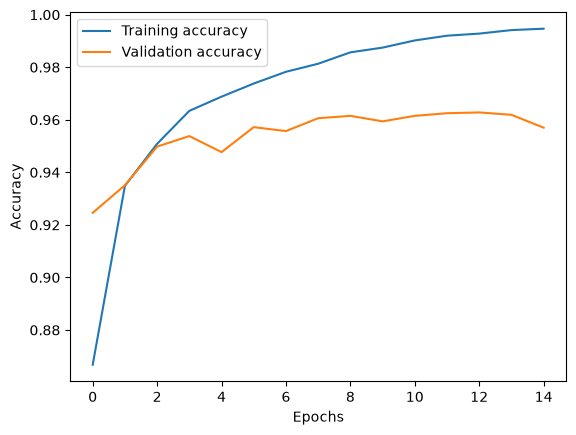

In [6]:
from model_2 import build

global_model = build.build_model()
initial_weights = global_model.get_weights()
local_model = build.build_model()
local_model.set_weights(initial_weights)

train_and_verify(
    local_model,
    x_local,
    y_local,
    15,
    x_test,
    y_test,
    "lmodel_0.keras"
)

In [7]:
local_model = build.build_model()

print("INPUT:", local_model.input_shape)
print("OUTPUT:", local_model.output_shape)

local_model.summary()

INPUT: (None, 28, 28, 1)
OUTPUT: (None, 10)


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
## Abrir los modelos:

import os
loaded_local_models = [tf.keras.models.load_model(f) for f in os.listdir(".") if f.startswith("lmodel_")]


for i in range(len(loaded_local_models)-1):
    assert loaded_local_models[i].summary() == loaded_local_models[i+1].summary(), "Models have different architectures"

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,102 (430.09 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,102 (430.09 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 55,052 (215.05 KB)

## Debug

In [10]:
local_weights = [x.get_weights() for x in loaded_local_models]
averaged_weights = [np.mean(np.array(weights), axis=0) for weights in zip(*local_weights)]

global_model = build.build_model()
global_model.set_weights(averaged_weights)

from sklearn.metrics import classification_report
# Predict the classes for the test set
y_pred = global_model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

global_model.save('global_model.keras')

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 328us/step
              precision    recall  f1-score   support

           0       0.98      0.94      0.96       980
           1       0.98      0.98      0.98      1135
           2       0.91      0.95      0.93      1032
           3       0.96      0.88      0.92      1010
           4       0.91      0.94      0.93       982
           5       0.85      0.93      0.89       892
           6       0.92      0.96      0.94       958
           7       0.92      0.92      0.92      1028
           8       0.90      0.94      0.92       974
           9       0.95      0.85      0.90      1009

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 646us/step - accuracy: 0.9197 - loss: 0.2797 - val_accuracy: 0.9559 - val_loss: 0.1422
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 523us/step - accuracy: 0.9602 - loss: 0.1325 - val_accuracy: 0.9647 - val_loss: 0.1146
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 526us/step - accuracy: 0.9699 - loss: 0.0998 - val_accuracy: 0.9698 - val_loss: 0.1020
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 527us/step - accuracy: 0.9749 - loss: 0.0820 - val_accuracy: 0.9736 - val_loss: 0.0909
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 527us/step - accuracy: 0.9787 - loss: 0.0707 - val_accuracy: 0.9757 - val_loss: 0.0910
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 553us/step - accuracy: 0.9820 - loss: 0.0618 - val_accuracy: 0.9743 - val_loss: 0.0974
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 594us/step - accuracy: 0.9839 - loss: 0.0548 - val_accuracy: 0.9737 - val_loss: 0.0951
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 531us/step - accuracy: 0.9858 -

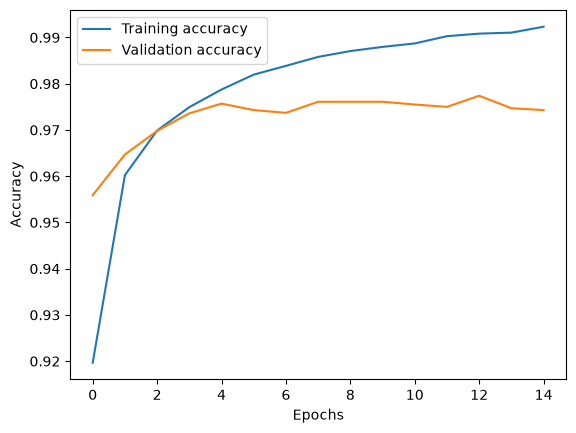

In [12]:
## VS A NORMAL GLOBLA MODEL TRAINED IN A SINGLE DEVICE:
train, test = tf.keras.datasets.mnist.load_data()

x_train, x_test = np.expand_dims(train[0] / 255.0, -1), np.expand_dims(test[0] / 255.0, -1)
y_train, y_test = train[1], test[1]

model = build.build_model()

history = model.fit(x_train, y_train, epochs=15, validation_data=(x_test, y_test))

from sklearn.metrics import classification_report
# Predict the classes for the test set
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

# Optionally, plot training history
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Bibliography:

https://www.tensorflow.org/guide/keras/training_with_built_in_methods
